In [17]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')


Model is ready


In [18]:
from dotenv import load_dotenv, find_dotenv
import os

env_path = find_dotenv()
load_dotenv(env_path)

tavilyApiKey = os.getenv('TAVILY_API_KEY')
print('Tavily API Key is ready')

Tavily API Key is ready


In [27]:
# Tools definition
from langchain_community.tools import tool
from tavily import TavilyClient
from langchain_community.tools import TavilySearchResults

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_stock_price(stock: str) -> str:
    """Returns the stock price for a given stock"""
    return f"The stock price of {stock} is 25.50"

@tool
def get_news(country: str) -> str:
    """Returns the news for a given country"""
    tavily_client = TavilySearchResults(max_results=3, api_key=tavilyApiKey)
    result = tavily_client.invoke({"query": f"Today's Breaking news in {country}"})
    return f"Tavily search result: {result}"

ALL_TOOLS = [get_weather, get_stock_price, get_news]
print('Tools are ready')

Tools are ready


In [28]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [29]:
# STEP 2: Define your nodes

model_with_tools = model.bind_tools(ALL_TOOLS)

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model_with_tools.invoke(state['messages'])
    return {"messages": [response]}

def route_after_assistant_node(state: AgentState) -> str:
    """Route to tools only when model produces tool calls"""
    last_message = state['messages'][-1]
    if last_message.tool_calls:
        return "tools_key"
    return "end_key"
print('Nodes are defined')

Nodes are defined


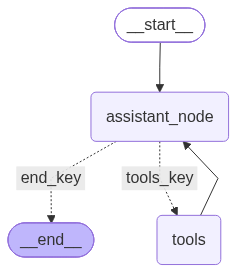

In [30]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_conditional_edges(
    "assistant_node",
    route_after_assistant_node,
    {
        "tools_key": "tools",
        "end_key": END
    }
)
graph_builder.add_edge("tools", "assistant_node")
graph = graph_builder.compile()
graph

In [6]:
response = graph.invoke({"messages": [{"role": "user", "content": "How is the weather in Pune today?"}]})
response

{'messages': [HumanMessage(content='How is the weather in Pune today?', additional_kwargs={}, response_metadata={}, id='246c0378-cccf-4a91-a00c-5f4131d095bf'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-26T03:42:32.276981285Z', 'done': True, 'done_reason': 'stop', 'total_duration': 315070214, 'load_duration': None, 'prompt_eval_count': 154, 'prompt_eval_duration': None, 'eval_count': 53, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1764d-7a53-7b31-97ba-7176877a34af-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'Pune'}, 'id': 'c70c10bf-a400-492d-a893-b635c6e54c41', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 154, 'output_tokens': 53, 'total_tokens': 207}),
  ToolMessage(content='The weather in the city Pune is Sunny', name='get_weather', id='0a9b037c-7582-4344-960c-4068432bfd64', tool_call_id='c70c10bf-a4

In [7]:
response = graph.invoke({"messages": [{"role": "user", "content": "Who is the president of India?"}]})
response

{'messages': [HumanMessage(content='Who is the president of India?', additional_kwargs={}, response_metadata={}, id='d482952a-5b98-47a9-bb1d-344822c73be2'),
  AIMessage(content="As of\u202f26\u202fOctober\u202f2026, the President of India is **Droupadi\u202fMurmu**. She took office on\u202f25\u202fJuly\u202f2022, becoming the nation’s 15th president and the first person from India's tribal community to hold the position. Her five‑year term is set to run until\u202f2027.", additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-26T03:42:46.373905141Z', 'done': True, 'done_reason': 'stop', 'total_duration': 813414921, 'load_duration': None, 'prompt_eval_count': 153, 'prompt_eval_duration': None, 'eval_count': 171, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1764d-acba-71e1-b146-409690760f23-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 153, 'output_tokens': 

In [31]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is the today's breaking news in India?"}]})
response

{'messages': [HumanMessage(content="What is the today's breaking news in India?", additional_kwargs={}, response_metadata={}, id='1ae2bb74-d475-461e-8a21-cf9fefc5995d'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-26T04:07:42.594203498Z', 'done': True, 'done_reason': 'stop', 'total_duration': 756148998, 'load_duration': None, 'prompt_eval_count': 179, 'prompt_eval_duration': None, 'eval_count': 69, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17664-8456-78a2-b0f5-60fe8d9f2b7a-0', tool_calls=[{'name': 'get_news', 'args': {'country': 'India'}, 'id': 'dfb9cdad-929f-46e6-98ef-9009e1a80c92', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 179, 'output_tokens': 69, 'total_tokens': 248}),
  ToolMessage(content='Tavily search result: [{\'title\': \'India Latest News: Top National Headlines Today & Breaking News - The Hindu\', \